## <b>[Github Link](https://github.com/VitorTavares-cct/CA1_Machine-Learning)</b>

In [1]:
import nflreadpy as nfl

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error, r2_score, confusion_matrix
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, MinMaxScaler, StandardScaler, RobustScaler, Normalizer
from sklearn.decomposition import PCA


In [2]:
pbp = nfl.load_pbp([2023, 2024, 2025]).to_pandas()
ftn = nfl.load_ftn_charting([2023,2024,2025]).to_pandas()
ptcp = nfl.load_participation([2023,2024,2025]).to_pandas()

print(list(pbp.columns))
print(list(ftn.columns))
print(list(ptcp.columns))

['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team', 'season_type', 'week', 'posteam', 'posteam_type', 'defteam', 'side_of_field', 'yardline_100', 'game_date', 'quarter_seconds_remaining', 'half_seconds_remaining', 'game_seconds_remaining', 'game_half', 'quarter_end', 'drive', 'sp', 'qtr', 'down', 'goal_to_go', 'time', 'yrdln', 'ydstogo', 'ydsnet', 'desc', 'play_type', 'yards_gained', 'shotgun', 'no_huddle', 'qb_dropback', 'qb_kneel', 'qb_spike', 'qb_scramble', 'pass_length', 'pass_location', 'air_yards', 'yards_after_catch', 'run_location', 'run_gap', 'field_goal_result', 'kick_distance', 'extra_point_result', 'two_point_conv_result', 'home_timeouts_remaining', 'away_timeouts_remaining', 'timeout', 'timeout_team', 'td_team', 'td_player_name', 'td_player_id', 'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'total_home_score', 'total_away_score', 'posteam_score', 'defteam_score', 'score_differential', 'posteam_score_post', 'defteam_score_post', 'score_differential

# Extraction

## About the Dataset
The dataset used for the Continuous Assessment is provenient from <b>nflreadpy</b> API, which provides NFL games statistics. From the multiple endpoints avialable, <b>load_pbp</b> (play by play), <b>ftn_charting</b> and <b>load_participation()</b> were selected, collecting data from every single play.

The following analysis will be based on <b>NFL Seasons</b> from 2023 to 2025 seasons.

Check [API Reference](https://nflreadpy.nflverse.com/api/load_functions/#nflreadpy.load_pbp) for more details.

## Columns Selected

### <b>load_pbp()</b>
#### Features Extracted
- game_id (str): NFL game id describing year, game number, away team and home team.
- qtr (int): Quarter which row happened, from 1 to 4 for regular period and 5 for overtime.
- down (int): Down from the play, from 1 to 4.
- ydstogo (int): Amount of yards to first down.
- play_type (enum): Type of play between run or pass.
- yards_gained (int): Amount of yards gained on play.
- yardline_100 (int): Total yards until defensive endzone.
- epa (float): Expected Points Added, a metric created by the NFL to measure the value of a play in the probability to score.
- success (bool): Success indicates if epa was positive (1) or if epa was negative (0).
- score_differential (int): Offensive Team Score - Defensive Team Score on the play.
- td_prob (float): Probability of Touchdown on drive.
- wp (float): Win Probability for the offensive team.
- air_yards (int): Amount of yards which the ball travelled until hits the receiver.
- interception (bool): If the result of the play was a defensive interception, the value is going to be 1, otherwise it is going to be 0.
- fumble_lost (bool): If the result of the play was the offense losing the ball possesion through a fumble, the value is going to be 1, otherwise it is going to be 0.
- qb_kneel (bool): If the QB took a knee on the play, the value is going to be 1, otherwise is going to be 0.
- qb_spike (bool): If the QB throw the ball on the ground to stop the clock is going to be 1, otherwise is going to be 0.
- incomplete_pass (bool): If the pass was incompleted, the value is going to be 1, otherwise is going to be 0.
- sack (bool): If the pass atempt ended as a QB Sacked, the value is going to be 1, otherwise is going to be 0.

#### Created Features
- turnover (bool): True whenever the play ended in fumble lost or interception (not including tornover on downs).

### <b>load_ftn_charting()</b>

#### Features Extracted

#### Features Created
- is_blitz (bool): True if there are 1 or more players on blitz.

### <b>load_participation</b>

#### Features Extracted

In [3]:
ptcp.head()

,nflverse_game_id,old_game_id,play_id,possession_team,offense_formation,offense_personnel,defenders_in_box,defense_personnel,number_of_pass_rushers,players_on_play,...,was_pressure,route,defense_man_zone_type,defense_coverage_type,offense_names,defense_names,offense_positions,defense_positions,offense_numbers,defense_numbers
0,2023_01_ARI_WAS,2023091007,39.0,WAS,None,"2 CB, 2 DE, 1 FS, 2 MLB, 1 OLB, 2 RB, 1 TE",0.0,"4 CB, 2 ILB, 1 K, 2 OLB, 1 SS, 1 WR",0.0,00-0032933;00-0034623;00-0035150;00-0037747;00...,...,False,,,None,Christian Holmes;Jartavius Martin;Casey Toohil...,Antonio Hamilton;Andre Chachere;Kris Boyd;Chri...,CB;CB;DE;DE;FS;MLB;MLB;OLB;RB;RB;TE,CB;CB;CB;CB;ILB;ILB;K;OLB;OLB;SS;WR,34;20;95;50;39;51;47;52;24;23;87,33;36;29;35;47;51;5;52;43;22;0
1,2023_01_ARI_WAS,2023091007,55.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR",6.0,"2 CB, 2 DE, 1 DT, 1 FS, 2 ILB, 2 OLB, 1 SS",0.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,,,None,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;TE;WR;WR,CB;CB;DE;DE;DT;FS;ILB;ILB;OLB;OLB;SS,63;71;14;8;72;77;76;82;87;17;1,20;13;91;93;95;34;7;10;25;52;3
2,2023_01_ARI_WAS,2023091007,77.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",4.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,HITCH/CURL,ZONE_COVERAGE,COVER_3,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;FS;ILB;ILB;OLB;OLB;SS;SS,63;71;14;8;72;77;76;82;4;17;1,20;13;91;93;34;7;10;25;97;3;22
3,2023_01_ARI_WAS,2023091007,102.0,WAS,UNDER CENTER,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",6.0,"2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS",0.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,,,None,Nick Gates;Andrew Wylie;Sam Howell;Chris Rodri...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;FS;ILB;ILB;OLB;OLB;SS;SS,63;71;14;23;72;77;76;82;4;17;1,20;13;91;93;34;7;10;25;97;3;22
4,2023_01_ARI_WAS,2023091007,124.0,WAS,SHOTGUN,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR",5.0,"2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS",4.0,00-0034445;00-0036884;00-0038984;00-0035636;00...,...,False,IN/DIG,ZONE_COVERAGE,COVER_4,Nick Gates;Andrew Wylie;Sam Howell;Brian Robin...,Marco Wilson;Kei'Trel Clark;L.J. Collier;Jonat...,C;G;QB;RB;T;T;T;TE;WR;WR;WR,CB;CB;DE;DE;DT;FS;ILB;OLB;OLB;SS;SS,63;71;14;8;72;77;76;82;4;17;1,20;13;91;93;95;34;7;45;25;3;22


In [4]:
defensive_plays = pbp[
    (pbp["play_type"].isin(["pass", "run"]))
    & (pbp["down"].notna())
].copy()

# FTN Columns
ftn_cols = [
    "nflverse_game_id", "nflverse_play_id", "qb_location",
    "n_offense_backfield", "n_blitzers", "n_pass_rushers",
    "is_motion", "is_play_action", "is_screen_pass",
    "is_qb_out_of_pocket",
    "read_thrown"
]

ftn = ftn[ftn_cols]
ftn = ftn.rename(columns={"nflverse_game_id": "game_id",
                       "nflverse_play_id": "play_id"})

# Participation Columns
ptcp_cols = [
    "nflverse_game_id", "play_id", "offense_formation",
    "offense_personnel", "defenders_in_box", "defense_personnel",
    "was_pressure", "defense_man_zone_type",
    "time_to_throw"
]

ptcp = ptcp[ptcp_cols]
ptcp = ptcp.rename(columns={"nflverse_game_id": "game_id"})

In [5]:
sample_cols = [
    "game_id", "play_id", "qtr", "down", "defteam", "ydstogo", "yardline_100",
    "play_type", "yards_gained", "epa", "success", "score_differential",
    "td_prob", "wp", "interception", "fumble_lost",
    "qb_kneel", "qb_spike", "incomplete_pass", "sack", "qb_hit", "qb_dropback", "season"
]

defensive_plays = defensive_plays[sample_cols]

defensive_plays["turnover"] = ((defensive_plays["interception"] == 1) | (defensive_plays["fumble_lost"] == 1)).astype(int)


# Merging Complementary Data
defensive_plays = pd.merge(defensive_plays, ftn, how="left", on=["game_id","play_id"])
defensive_plays = pd.merge(defensive_plays, ptcp, how="left", on=["game_id","play_id"])

defensive_plays["is_blitz"] = defensive_plays["n_blitzers"] > 0

def get_position_count(value, position):
    for number in value.split(","):
        if position in number:
            return int(number.strip().split()[0])

offensive_positions_list = ["RB", "TE", "WR"]
defensive_position_list = ["DE", "DT", "NT", "CB", "FS", "SS", "ILB", "OLB"]

for position in offensive_positions_list:
    defensive_plays[position] = defensive_plays["offense_personnel"].apply(lambda x: get_position_count(x, position)).fillna(0)

for position in defensive_position_list:
    defensive_plays[position] = defensive_plays["defense_personnel"].apply(lambda x: get_position_count(x, position)).fillna(0)

defensive_plays["defensive_line"] = defensive_plays["DT"] + defensive_plays["DE"] + defensive_plays["NT"]
defensive_plays["linebackers"] = defensive_plays["ILB"] + defensive_plays["OLB"]
defensive_plays["defensive_backs"] = defensive_plays["CB"] + defensive_plays["SS"] + defensive_plays["FS"]

defensive_plays["eligible_formation"] = defensive_plays["WR"].astype(int).astype(str) + "-" + defensive_plays["RB"].astype(int).astype(str) + "-" + defensive_plays["TE"].astype(int).astype(str)
defensive_plays["defense_structure"] = defensive_plays["defensive_line"].astype(int).astype(str) + "-" + defensive_plays["linebackers"].astype(int).astype(str) + "-" + defensive_plays["defensive_backs"].astype(int).astype(str)

# Creating a Colts subset
colts_defensive_plays = defensive_plays[defensive_plays['defteam'] == "IND"]

# Creating a subset without Colts
without_colts_defensive_plays = defensive_plays[defensive_plays['defteam'] != "IND"]

In [6]:
defensive_plays[["offense_personnel", "defense_personnel"]]

,offense_personnel,defense_personnel
0,"1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR","2 CB, 2 DE, 1 DT, 1 FS, 2 ILB, 2 OLB, 1 SS"
1,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS"
2,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 FS, 2 ILB, 2 OLB, 2 SS"
3,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS"
4,"1 C, 1 G, 1 QB, 1 RB, 3 T, 1 TE, 3 WR","2 CB, 2 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS"
...,...,...
104873,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR","3 CB, 1 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS"
104874,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR","3 CB, 1 DE, 1 DT, 1 FS, 1 ILB, 2 OLB, 2 SS"
104875,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR","3 CB, 1 DE, 1 FS, 1 ILB, 1 NT, 2 OLB, 2 SS"
104876,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR","3 CB, 1 DE, 1 FS, 1 ILB, 1 NT, 2 OLB, 2 SS"


In [7]:
colts_defensive_plays

,game_id,play_id,qtr,down,defteam,ydstogo,yardline_100,play_type,yards_gained,epa,...,CB,FS,SS,ILB,OLB,defensive_line,linebackers,defensive_backs,eligible_formation,defense_structure
994,2023_01_JAX_IND,143.0,1.0,1.0,IND,10.0,63.0,pass,0.0,-0.510003,...,3.0,2.0,0.0,0.0,1.0,4.0,1.0,5.0,3-1-1,4-1-5
995,2023_01_JAX_IND,166.0,1.0,2.0,IND,10.0,63.0,pass,6.0,-0.091518,...,3.0,2.0,0.0,0.0,1.0,4.0,1.0,5.0,3-1-1,4-1-5
996,2023_01_JAX_IND,191.0,1.0,3.0,IND,4.0,57.0,pass,0.0,-1.842414,...,3.0,2.0,0.0,0.0,2.0,4.0,2.0,5.0,3-1-1,4-2-5
1000,2023_01_JAX_IND,329.0,1.0,1.0,IND,10.0,61.0,run,0.0,-0.535897,...,3.0,2.0,0.0,0.0,1.0,4.0,1.0,5.0,3-1-1,4-1-5
1001,2023_01_JAX_IND,358.0,1.0,2.0,IND,10.0,61.0,pass,9.0,0.729804,...,3.0,2.0,0.0,0.0,1.0,4.0,1.0,5.0,3-1-1,4-1-5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102256,2025_18_IND_HOU,4281.0,4.0,2.0,IND,3.0,58.0,pass,17.0,0.898919,...,3.0,1.0,1.0,0.0,1.0,4.0,1.0,5.0,3-0-1,4-1-5
102257,2025_18_IND_HOU,4313.0,4.0,1.0,IND,10.0,41.0,pass,13.0,0.598170,...,2.0,1.0,1.0,0.0,1.0,5.0,1.0,4.0,3-0-1,5-1-4
102258,2025_18_IND_HOU,4345.0,4.0,1.0,IND,10.0,28.0,run,2.0,-0.256910,...,2.0,1.0,1.0,0.0,1.0,5.0,1.0,4.0,2-0-2,5-1-4
102259,2025_18_IND_HOU,4374.0,4.0,2.0,IND,8.0,26.0,run,1.0,-0.460872,...,2.0,1.0,1.0,0.0,1.0,5.0,1.0,4.0,2-0-2,5-1-4


## Data Cleaning

`n_offense_backfield`: there are no situations of expected NaN for this feature, if it is further relevant for models, NaN rows are going to be dropped.

`n_pass_rushers`: there are no situations of expected NaN for this feature, if it is further relevant for models, NaN rows are going to be dropped.

`offense_formation`: there are no situations of expected NaN for this feature, if it is further relevant for models, NaN rows are going to be dropped.

`time_to_throw`: it is expected to have NaN values whenever the play is a run, however it should be kept since it is going to be used only on regression models with an average, so NaN values should not be considered in this feature extraction.

### Removing Plays
In NFL, there are plays which the intention of executing it is just manage the clock. A <b>Spike</b> is when a offense throw the ball on the ground to stop the clock, preserving it, and a <b>Kneel</b> is when a offense take a knee to kill time. Both type of plays are going to be removed, since there is no intention on gaining yards.

In [8]:
defensive_plays.isnull().sum()

game_id                      0
play_id                      0
qtr                          0
down                         0
defteam                      0
ydstogo                      0
yardline_100                 0
play_type                    0
yards_gained                 0
epa                          0
success                      0
score_differential           0
td_prob                      0
wp                           0
interception                 0
fumble_lost                  0
qb_kneel                     0
qb_spike                     0
incomplete_pass              0
sack                         0
qb_hit                       0
qb_dropback                  0
season                       0
turnover                     0
qb_location                  0
n_offense_backfield       1065
n_blitzers                   0
n_pass_rushers             766
is_motion                    0
is_play_action               0
is_screen_pass               0
is_qb_out_of_pocket          0
read_thr

In [9]:
df_list = [defensive_plays, without_colts_defensive_plays, colts_defensive_plays]

for df in df_list:
    # Removing plays without offensive goals
    df['qb_kneel'] = df['qb_kneel'].astype(int)
    df['qb_spike'] = df['qb_spike'].astype(int)
    df = df[(df['qb_kneel'] != 1) & (df['qb_spike'] != 1)]

C:\Users\Vitor\AppData\Local\Temp\ipykernel_30088\4038290327.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['qb_kneel'] = df['qb_kneel'].astype(int)
C:\Users\Vitor\AppData\Local\Temp\ipykernel_30088\4038290327.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['qb_spike'] = df['qb_spike'].astype(int)
C:\Users\Vitor\AppData\Local\Temp\ipykernel_30088\4038290327.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

# Play Type Prediction

In [10]:
play_type_df = colts_defensive_plays[['down', 'ydstogo',
                                    'score_differential', 'td_prob',
                                    'qb_location', 'n_offense_backfield', 'offense_formation', "yardline_100",
                                    'RB', 'TE', 'WR', 'defensive_line', 'linebackers', 'defensive_backs',
                                    'play_type']]

play_type_df = play_type_df.dropna(axis=0)

play_type_df.shape

(3276, 15)

In [11]:
play_type_df.isna().sum()

down                   0
ydstogo                0
score_differential     0
td_prob                0
qb_location            0
n_offense_backfield    0
offense_formation      0
yardline_100           0
RB                     0
TE                     0
WR                     0
defensive_line         0
linebackers            0
defensive_backs        0
play_type              0
dtype: int64

In [12]:
le = LabelEncoder()
oe = OrdinalEncoder()

def ordinal_encoder(df, list):
    for column in list:
        df[column] = oe.fit_transform(df[[column]])

ordinal_cols = ["offense_formation", "qb_location"]


ordinal_encoder(play_type_df, ordinal_cols)

play_type_df['play_type'] = le.fit_transform(play_type_df['play_type'])

classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [13]:
# Training with different test sizes
test_size_list = [0.05, 0.15, 0.2, 0.25]

for size in test_size_list:
    X = play_type_df.drop(columns='play_type')
    y = play_type_df['play_type']   

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size, random_state = 42)

    # Train and evaluate ML model classifiers for Obesity dataset
    results = []
    for name, classifier in classifiers.items():
        # Train the classifier
        classifier.fit(X_train, y_train)
        
        # Predict on the test set
        y_pred = classifier.predict(X_test)
        
        # Calculate performance metrics
        accuracy = accuracy_score(y_test, y_pred)
        report = classification_report(y_test, y_pred, output_dict=True)
        precision = report['weighted avg']['precision']
        recall = report['weighted avg']['recall']
        f1_score = report['weighted avg']['f1-score']
        
        # Append results
        results.append([name, accuracy, precision, recall, f1_score])

        # Convert results to DataFrame for easy viewing
        results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
        print(f"Model Performance Metrics on Test Set with size {size}:")
        print(results_df)


Model Performance Metrics on Test Set with size 0.05:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.603659   0.608537  0.603659  0.605544
Model Performance Metrics on Test Set with size 0.05:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.603659   0.608537  0.603659  0.605544
1        Decision Tree  0.670732   0.669303  0.670732  0.669917
Model Performance Metrics on Test Set with size 0.05:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.603659   0.608537  0.603659  0.605544
1        Decision Tree  0.670732   0.669303  0.670732  0.669917
2        Random Forest  0.743902   0.745223  0.743902  0.744452
Model Performance Metrics on Test Set with size 0.05:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.603659   0.608537  0.603659  0.605544
1        Decision Tree  0.670732   0.669303  0.670732  0.669917
2        Random 

In [14]:
X = play_type_df.drop(columns='play_type')
y = play_type_df['play_type']   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [15]:
# Train and evaluate ML model classifiers for Obesity dataset
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [16]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.582418   0.576434  0.582418  0.571915
1           Decision Tree  0.639805   0.637630  0.639805  0.637540
2           Random Forest  0.715507   0.714573  0.715507  0.714565
3     Logistic Regression  0.721612   0.723659  0.721612  0.716808
4  Support Vector Machine  0.720391   0.722788  0.720391  0.715260


In [17]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.581806
1           Decision Tree          0.648956
2           Random Forest          0.730466
3     Logistic Regression          0.703592
4  Support Vector Machine          0.698100


In [18]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel='linear', random_state=42),
}

In [19]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 0.5, 1, 10],
        # "solver": ['lbfgs', 'liblinear'],
        # "penalty": ['l2']
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20, 30],
        # "min_samples_split": [2, 5, 10],
        # "min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 5, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    },
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9, 11],
        # "algorithm": ['auto', 'ball_tree', 'kd_tree', 'brute']     #The "algorithm" parameter in the KNeighborsClassifier controls how the nearest neighbors search is performed. It determines the method used to compute distances between points in the feature space and find the nearest neighbors. There are four options for the "algorithm"
    },
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ['linear', 'rbf'],
        # "gamma": ['scale', 'auto']
    }
}

In [20]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 135 candidates, totalling 675 fits
Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Running GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [21]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                    Model  Accuracy  Precision    Recall  F1 Score  \
0     Logistic Regression  0.721612   0.723659  0.721612  0.716808   
1           Decision Tree  0.732601   0.731862  0.732601  0.731913   
2           Random Forest  0.753358   0.752789  0.753358  0.752851   
3     k-Nearest Neighbors  0.611722   0.608093  0.611722  0.606349   
4  Support Vector Machine  0.715507   0.717906  0.715507  0.710074   

                                     Best Parameters  
0                                           {'C': 1}  
1                                   {'max_depth': 5}  
2  {'max_depth': 10, 'min_samples_leaf': 4, 'min_...  
3                                 {'n_neighbors': 3}  
4                     {'C': 0.1, 'kernel': 'linear'}  


In [22]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 135 candidates, totalling 675 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [23]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                    Model  Mean CV Accuracy
0     Logistic Regression          0.703592
1           Decision Tree          0.719478
2           Random Forest          0.752444
3     k-Nearest Neighbors          0.589441
4  Support Vector Machine          0.699319


<Figure size 640x480 with 0 Axes>

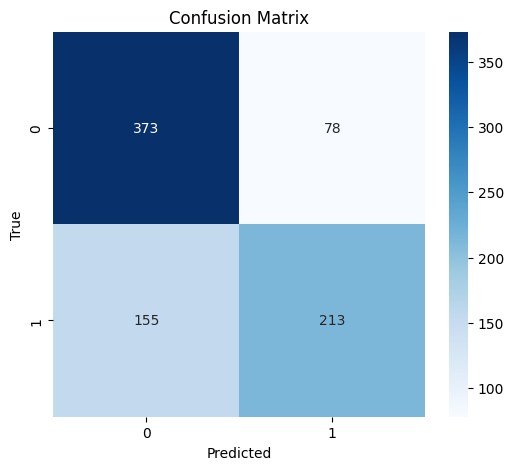

In [24]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# **Ensure previous plots are cleared**
plt.clf()  # Clear the previous plot before rendering a new one
plt.figure(figsize = (6, 5))  # Define figure size to avoid residual elements

# Create a heatmap for the confusion matrix
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels=['0', '1'], 
            yticklabels=['0', '1'])

# Add labels and title
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Show the plot
plt.show()

# EPA Regression

In [25]:
epa_df = without_colts_defensive_plays.groupby(
    ["game_id", "defteam"]
).agg(
    avg_epa_per_play = ("epa", "mean"),
    avg_defenders_in_box = ("defenders_in_box", "mean"),
    avg_rb_per_play = ("RB", "mean"),
    avg_wr_per_play = ("WR", "mean"),
    avg_te_per_play = ("TE", "mean"),
    avg_dline_per_play = ("defensive_line", "mean"),
    avg_lb_per_play = ("linebackers", "mean"),
    avg_db_per_play = ("defensive_backs", "mean"),
    avg_yards_to_go = ("ydstogo", "mean"),
    avg_score_differential = ("score_differential", "mean"),
    avg_field_position = ("yardline_100", "mean")
).reset_index()



formation_dummies = pd.get_dummies(without_colts_defensive_plays["offense_formation"])
formation_rate = (pd.concat([without_colts_defensive_plays[["game_id", "defteam"]], formation_dummies], axis=1).groupby(["game_id", "defteam"])
                  .mean()
                  .reset_index())

epa_df = epa_df.merge(formation_rate, on=["game_id", "defteam"], how="left")
epa_df["avg_field_position"] = StandardScaler().fit_transform(epa_df[["avg_field_position"]])

In [26]:
epa_df = epa_df.dropna()
print(f"Null Count: \n{epa_df.isnull().sum()}")
print(f"\nShape: \n{epa_df.shape}")

Null Count: 
game_id                   0
defteam                   0
avg_epa_per_play          0
avg_defenders_in_box      0
avg_rb_per_play           0
avg_wr_per_play           0
avg_te_per_play           0
avg_dline_per_play        0
avg_lb_per_play           0
avg_db_per_play           0
avg_yards_to_go           0
avg_score_differential    0
avg_field_position        0
PISTOL                    0
SHOTGUN                   0
UNDER CENTER              0
dtype: int64

Shape: 
(1659, 16)


In [27]:
epa_df.head()

,game_id,defteam,avg_epa_per_play,avg_defenders_in_box,avg_rb_per_play,avg_wr_per_play,avg_te_per_play,avg_dline_per_play,avg_lb_per_play,avg_db_per_play,avg_yards_to_go,avg_score_differential,avg_field_position,PISTOL,SHOTGUN,UNDER CENTER
0,2023_01_ARI_WAS,ARI,-0.294184,5.046154,1.000000,2.661538,1.338462,2.246154,3.938462,4.800000,9.230769,-1.415385,0.217984,0.000000,0.784615,0.184615
1,2023_01_ARI_WAS,WAS,-0.352051,5.982759,1.000000,2.517241,1.413793,4.189655,0.655172,5.155172,9.706897,-0.551724,1.707916,0.000000,0.706897,0.293103
2,2023_01_BUF_NYJ,BUF,-0.047413,6.529412,1.156863,2.176471,1.666667,4.000000,2.000000,5.000000,8.705882,-5.215686,-0.326893,0.000000,0.490196,0.509804
3,2023_01_BUF_NYJ,NYJ,-0.067782,5.462687,0.955224,2.268657,1.716418,3.298507,2.761194,4.940299,9.149254,2.641791,0.977675,0.000000,0.925373,0.074627
4,2023_01_CAR_ATL,ATL,-0.269806,5.833333,0.944444,2.986111,1.069444,2.750000,3.319444,4.930556,9.083333,-5.041667,0.903028,0.263889,0.666667,0.069444


In [28]:
# Training with different test sizes
test_size_list = [0.05, 0.15, 0.2, 0.25]

# Models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

for size in test_size_list:
    X = epa_df.drop(columns=['avg_epa_per_play',"game_id","defteam"])
    y = epa_df['avg_epa_per_play']   

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size, random_state = 42)

    # Store results
    results = []

    # Train and evaluate models
    for name, model in models.items():
        # Train the model
        model.fit(X_train, y_train)
        
        # Predict on the test set
        y_pred = model.predict(X_test)
        
        # Calculate performance metrics
        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, y_pred)
        
        # Append results to the list
        results.append([name, mae, mse, rmse, r2])

    # Create a DataFrame to display the results
    results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
    print(f"Results with test size {size}:\n{results_df}")



Results with test size 0.05:
               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.132141  0.025605  0.160015    0.344907
1      Decision Tree  0.180206  0.054689  0.233856   -0.399197
2      Random Forest  0.127221  0.025392  0.159350    0.350344
Results with test size 0.15:
               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.129473  0.025736  0.160424    0.408557
1      Decision Tree  0.179416  0.055229  0.235009   -0.269248
2      Random Forest  0.134783  0.028616  0.169164    0.342354
Results with test size 0.2:
               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.131173  0.027475  0.165754    0.363450
1      Decision Tree  0.173478  0.046860  0.216472   -0.085689
2      Random Forest  0.133418  0.028107  0.167652    0.348790
Results with test size 0.25:
               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.130349  0.027090  0.164590    0.396023
1  

In [29]:
X = epa_df.drop(columns=['avg_epa_per_play',"game_id","defteam"])
y = epa_df['avg_epa_per_play']   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [30]:
param_grid = {
    'Linear Regression': {'alpha': [0.0025, 0.005, 0.01, 0.1, 1.0, 10.0, 20.0]},
    'Decision Tree': {'max_depth': [5, 10, 15, 20, 25]}, 
    'Random Forest': {'n_estimators': [25, 50, 100, 200]} 
}

# Models
models = {
    "Linear Regression": Ridge(random_state = 42),
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(random_state = 42)
}

# Store results
results = []

# Grid Search for hyperparameter tuning
for name, model in models.items():
    grid_search = GridSearchCV(model, param_grid[name], cv = 10, scoring = 'r2')  
    grid_search.fit(X, y)
    
    # Best parameters and best score
    best_params = grid_search.best_params_
    best_score  = grid_search.best_score_
    
    # Store results
    results.append([name, best_params, best_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Best Parameters", "Best CV R² Score"])
print("\nBest Hyperparameters and Scores from Grid Search:")
print(results_df)


Best Hyperparameters and Scores from Grid Search:
               Model        Best Parameters  Best CV R² Score
0  Linear Regression        {'alpha': 20.0}          0.448661
1      Decision Tree       {'max_depth': 5}          0.352742
2      Random Forest  {'n_estimators': 200}          0.435068


In [31]:
# Models
models = {
    "Linear Regression": Ridge(random_state=42, alpha=0.2),
    "Decision Tree": DecisionTreeRegressor(random_state = 42),
    "Random Forest": RandomForestRegressor(n_estimators = 100, random_state = 42)
}

In [32]:
# Store results
results = []

# Train and evaluate models
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    # Append results to the list
    results.append([name, mae, mse, rmse, r2])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", " MAE", " MSE", " RMSE", "  R2 Score"])
print(results_df)

               Model       MAE       MSE      RMSE    R2 Score
0  Linear Regression  0.128945  0.025947  0.161081    0.421507
1      Decision Tree  0.182999  0.053323  0.230918   -0.188851
2      Random Forest  0.135310  0.028435  0.168626    0.366040


In [33]:
# Store results
results = []

# Train and evaluate models using cross-validation for R² Score
for name, model in models.items():
    # Perform cross-validation
    cv_scores = cross_val_score(model, X, y, cv = 10, scoring = 'r2')  # Using R² for scoring
    mean_cv_score = cv_scores.mean()  # Mean R² score
    
    # Train the model on the full dataset for predictions
    model.fit(X, y)
    
    # Store results
    results.append([name, mean_cv_score])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)


Model Performance Metrics using Cross-Validation for R² Score:
               Model  Mean CV R² Score
0  Linear Regression          0.447311
1      Decision Tree         -0.201932
2      Random Forest          0.429872



Model Performance Metrics using Cross-Validation for R² Score:
               Model  Mean CV R² Score
0  Linear Regression          0.447311
1      Decision Tree         -0.201932
2      Random Forest          0.429872


C:\Users\Vitor\AppData\Local\Temp\ipykernel_30088\450972725.py:22: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color = 'red', lw = 2)  # Diagonal line


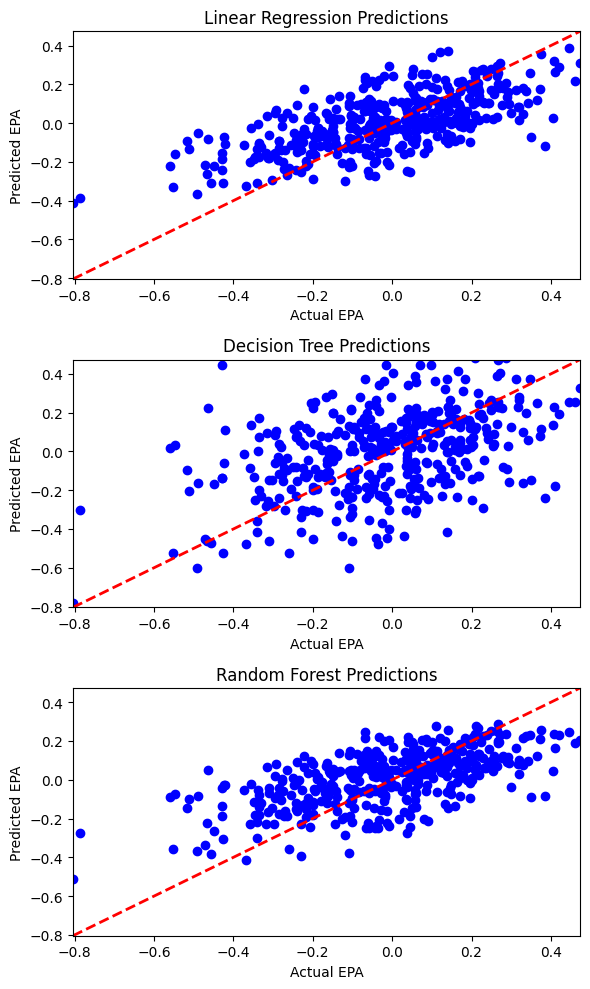

In [34]:
# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(results_df)

# To demonstrate predictions and plot results, let's still split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

# Predict on the test set for final evaluation
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

# Plotting actual vs predicted for each model vertically with smaller size
plt.figure(figsize = (6, 10))  # Adjusted size for a more compact vertical layout

for i, (name, y_pred) in enumerate(predictions.items()):
    plt.subplot(3, 1, i + 1)  # 3 rows, 1 column
    plt.scatter(y_test, y_pred, color = 'blue')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color = 'red', lw = 2)  # Diagonal line
    plt.title(f'{name} Predictions')
    plt.xlabel('Actual EPA')
    plt.ylabel('Predicted EPA')
    plt.xlim(y_test.min(), y_test.max())
    plt.ylim(y_test.min(), y_test.max())

plt.tight_layout()
plt.show()

## Testing with Colts Sample

In [35]:
colts_epa_df = colts_defensive_plays.groupby(
    ["game_id", "defteam"]
).agg(
    avg_epa_per_play = ("epa", "mean"),
    avg_defenders_in_box = ("defenders_in_box", "mean"),
    avg_rb_per_play = ("RB", "mean"),
    avg_wr_per_play = ("WR", "mean"),
    avg_te_per_play = ("TE", "mean"),
    avg_dline_per_play = ("defensive_line", "mean"),
    avg_lb_per_play = ("linebackers", "mean"),
    avg_db_per_play = ("defensive_backs", "mean"),
    avg_yards_to_go = ("ydstogo", "mean"),
    avg_score_differential = ("score_differential", "mean"),
    avg_field_position = ("yardline_100", "mean")
).reset_index()



formation_dummies = pd.get_dummies(colts_defensive_plays["offense_formation"])
formation_rate = (pd.concat([colts_defensive_plays[["game_id", "defteam"]], formation_dummies], axis=1).groupby(["game_id", "defteam"])
                  .mean()
                  .reset_index())

colts_epa_df = colts_epa_df.merge(formation_rate, on=["game_id", "defteam"], how="left")
colts_epa_df["avg_field_position"] = StandardScaler().fit_transform(colts_epa_df[["avg_field_position"]])

colts_eda_x = colts_epa_df.drop(columns=['avg_epa_per_play',"game_id","defteam"])

In [36]:
linear_regression_model = models["Linear Regression"]

In [37]:
colts_epa_df['epa_predicted'] = linear_regression_model.predict(colts_eda_x)
colts_epa_df["epa_diff"] = colts_epa_df["epa_predicted"] - colts_epa_df["avg_epa_per_play"]

In [38]:
colts_epa_df.head()

,game_id,defteam,avg_epa_per_play,avg_defenders_in_box,avg_rb_per_play,avg_wr_per_play,avg_te_per_play,avg_dline_per_play,avg_lb_per_play,avg_db_per_play,avg_yards_to_go,avg_score_differential,avg_field_position,PISTOL,SHOTGUN,UNDER CENTER,epa_predicted,epa_diff
0,2023_01_JAX_IND,IND,-0.233553,5.750000,1.014706,2.397059,1.573529,4.058824,1.397059,4.691176,7.617647,0.426471,-0.057932,0.117647,0.691176,0.176471,0.039850,0.273402
1,2023_02_IND_HOU,IND,-0.015504,5.513158,1.000000,2.644737,1.157895,3.973684,1.526316,4.776316,8.302632,-14.171053,0.255206,0.000000,0.710526,0.289474,-0.154007,-0.138503
2,2023_03_IND_BAL,IND,-0.144795,6.180556,1.000000,2.597222,1.083333,3.986111,1.500000,4.777778,8.027778,-0.902778,2.056975,0.027778,0.847222,0.125000,-0.136886,0.007909
3,2023_04_LA_IND,IND,0.175249,5.217949,1.000000,2.948718,1.051282,3.987179,1.474359,5.012821,8.653846,9.615385,0.460737,0.000000,0.615385,0.384615,0.064435,-0.110815
4,2023_05_TEN_IND,IND,0.099704,6.339286,1.125000,2.410714,1.464286,4.000000,2.017857,4.642857,8.535714,-3.732143,-0.055682,0.107143,0.446429,0.446429,-0.011856,-0.111560


In [39]:
colts_epa_df["epa_diff"].mean()

np.float64(0.003318853881417626)

C:\Users\Vitor\AppData\Local\Temp\ipykernel_30088\1502814149.py:2: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([colts_epa_df["avg_epa_per_play"].min(), colts_epa_df["avg_epa_per_play"].max()], [colts_epa_df["avg_epa_per_play"].min(), colts_epa_df["avg_epa_per_play"].max()], 'k--', color = 'red', lw = 2)  # Diagonal line


Text(0.5, 1.0, 'Real vs Predicted EPA')

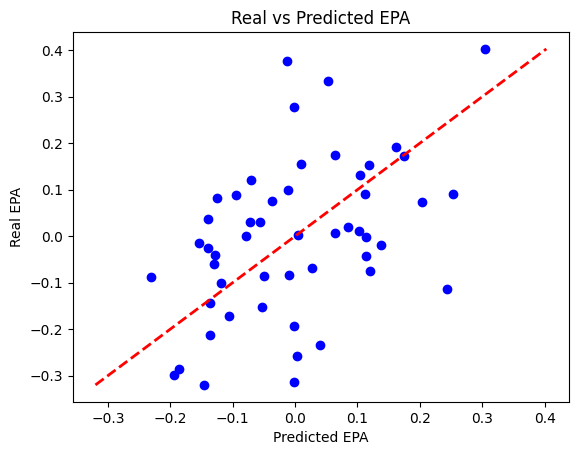

In [40]:
plt.scatter(colts_epa_df["epa_predicted"], colts_epa_df["avg_epa_per_play"], color = 'blue')
plt.plot([colts_epa_df["avg_epa_per_play"].min(), colts_epa_df["avg_epa_per_play"].max()], [colts_epa_df["avg_epa_per_play"].min(), colts_epa_df["avg_epa_per_play"].max()], 'k--', color = 'red', lw = 2)  # Diagonal line

plt.xlabel("Predicted EPA")
plt.ylabel("Real EPA")
plt.title("Real vs Predicted EPA")